# Statistically Validated Chronic Disease Transition Network Analysis

Builds the directed, weighted transition network across 25 chronic conditions (30,708 patients, 1,163,404 rows), tests each edge for statistical significance, computes centrality measures, and establishes the Diabetes to CVD pathway as the thesis's focus transition.

In [ ]:
import warnings; warnings.filterwarnings('ignore')
from pathlib import Path
from collections import defaultdict
from itertools import combinations
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors
import networkx as nx
from scipy.stats import ttest_1samp, chi2_contingency, fisher_exact

BASE = Path('/Users/tanyarusso/Library/Mobile Documents/com~apple~CloudDocs/University /ELEC4712/mapping_2.0')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.facecolor': '#f5f6fa'})

# ── Disease category colours ───────────────────────────────────────────────────
COND_CATEGORY = {
    'CVD':          ('CVD (outcome)',             '#c0392b'),
    'Diabetes':     ('Diabetes (cohort-defining)', '#27ae60'),
    'CKD':          ('Renal',                 '#2980b9'),
    'FluidsLytes':  ('Fluid/Electrolyte',     '#5d6d7e'),
    'Obesity':      ('Metabolic',             '#1e8449'),
    'Gout':         ('Metabolic',             '#1e8449'),
    'COPD':         ('Respiratory',           '#117a65'),
    'Asthma':       ('Respiratory',           '#117a65'),
    'Alcohol':      ('Mental Health/Substance', '#d35400'),
    'Drugs':        ('Mental Health/Substance', '#d35400'),
    'MHC':          ('Mental Health/Substance', '#d35400'),
    'Arthritis':    ('Musculoskeletal',       '#784212'),
    'BackPain':     ('Musculoskeletal',       '#784212'),
    'Osteo':        ('Musculoskeletal',       '#784212'),
    'Anemia':       ('Haematologic',          '#922b21'),
    'BloodLoss':    ('Haematologic',          '#922b21'),
    'Coagulopathy': ('Haematologic',          '#922b21'),
    'Liver':        ('Hepatic',               '#9b59b6'),
    'PUD':          ('Hepatic',               '#9b59b6'),
    'NeuroOther':   ('Neurologic',            '#1a5276'),
    'Paralysis':    ('Neurologic',            '#1a5276'),
    'Cancer':       ('Oncologic',             '#6c3483'),
    'Hypothyroid':  ('Endocrine (Other)',     '#b7950b'),
    'WeightLoss':   ('Constitutional/Frailty','#c2607d'),
    'HIV':          ('Other (not an ML category)', '#7b7d7d'),
}
COND_COL = {c: v[1] for c, v in COND_CATEGORY.items()}
SIG_COL  = {'***': '#1a7a1a', '**': '#2171b5', '*': '#c87000', 'ns': '#cccccc'}
print('Setup complete.')

Setup complete.


In [2]:
def load_csv(name):
    src = BASE / name
    tmp = Path('/tmp') / name
    shutil.copy2(src, tmp)
    return pd.read_csv(tmp, dtype=str, low_memory=False)

print('Loading data...')
df = load_csv('cbhs_chronic_patients_all_rows.csv')
df['_dt'] = pd.to_datetime(df['diagnosed_time'], dayfirst=True, errors='coerce')
has_chr = df['chronic_condition'].notna() & (df['chronic_condition'].str.strip() != '')

def parse_conds(val):
    if isinstance(val, str) and val.strip():
        return set(val.strip().split('|'))
    return set()
def union_conds(col):
    s = set()
    for v in col: s |= parse_conds(v)
    return s

ep_df = (
    df.loc[has_chr]
    .groupby(['person_id', 'episode_id'])
    .agg(ep_date=('_dt', 'min'), conditions=('chronic_condition', union_conds))
    .reset_index()
)
ep_df = ep_df[ep_df['conditions'].apply(len) > 0]
ALL_CONDS = sorted({c for conds in ep_df['conditions'] for c in conds})
N_TOTAL   = df['person_id'].nunique()
print(f'{len(df):,} rows | {N_TOTAL:,} patients | {len(ep_df):,} chronic episodes | {len(ALL_CONDS)} conditions')

# ── Patient counts: n_ever and first_cohort ────────────────────────────────────
n_ever       = defaultdict(int)   # all patients who ever had the condition
first_cohort = defaultdict(int)   # patients whose FIRST chronic dx was this condition
patient_cond_dates = {}
patient_next       = {}

for pid, grp in ep_df.groupby('person_id'):
    grp_s = grp.sort_values('ep_date', na_position='last')
    cond_dates = {}
    for _, row in grp_s.iterrows():
        if pd.isna(row['ep_date']): continue
        for c in row['conditions']:
            if c not in cond_dates or row['ep_date'] < cond_dates[c]:
                cond_dates[c] = row['ep_date']
    patient_cond_dates[pid] = cond_dates
    for c in cond_dates: n_ever[c] += 1

    # first-cohort
    if not grp_s.empty:
        min_date = grp_s['ep_date'].iloc[0]
        fc = set()
        for _, row in grp_s.iterrows():
            if row['ep_date'] == min_date: fc |= row['conditions']
            else: break
        for c in fc: first_cohort[c] += 1

    # patient_next map for t-test
    valid = sorted([(c, d) for c, d in cond_dates.items() if pd.notna(d)], key=lambda x: x[1])
    if not valid:
        patient_next[pid] = {}; continue
    groups, cur_date, cur_group = [], None, []
    for cond, date in valid:
        if date == cur_date: cur_group.append(cond)
        else:
            if cur_group: groups.append(cur_group)
            cur_date, cur_group = date, [cond]
    if cur_group: groups.append(cur_group)
    patient_next[pid] = {c: set(groups[i+1]) if i+1 < len(groups) else set()
                         for i, group in enumerate(groups) for c in group}

print('Patient timelines built.')
print(f'\n{"Condition":<16}  {"n_ever":>8}  {"first_cohort":>13}  {"ratio":>7}')
print('-' * 50)
for c in sorted(ALL_CONDS, key=lambda x: -n_ever[x]):
    ne, fc = n_ever[c], first_cohort.get(c, 0)
    print(f'  {c:<14}  {ne:>8,}  {fc:>13,}  {ne/fc:.2f}x' if fc else f'  {c:<14}  {ne:>8,}  {"—":>13}')

Loading data...


1,163,404 rows | 30,708 patients | 127,052 chronic episodes | 25 conditions


Patient timelines built.

Condition           n_ever   first_cohort    ratio
--------------------------------------------------
  CVD                8,820          6,668  1.32x
  Osteo              6,859          5,387  1.27x
  Cancer             5,728          4,581  1.25x
  Diabetes           5,156          4,033  1.28x
  BackPain           3,581          2,595  1.38x
  FluidsLytes        3,468          1,800  1.93x
  MHC                1,983          1,527  1.30x
  Asthma             1,942          1,726  1.13x
  Obesity            1,782          1,384  1.29x
  Anemia             1,527          1,016  1.50x
  NeuroOther         1,384            944  1.47x
  WeightLoss         1,191            543  2.19x
  COPD                 940            508  1.85x
  CKD                  915            332  2.76x
  Coagulopathy         790            389  2.03x
  Alcohol              722            530  1.36x
  Liver                649            420  1.55x
  Arthritis            562            3

## 1. Patient Counts Per Chronic Condition

Prevalence (n_ever, any diagnosis) vs. incidence cohort (first_cohort, first chronic diagnosis) per condition.

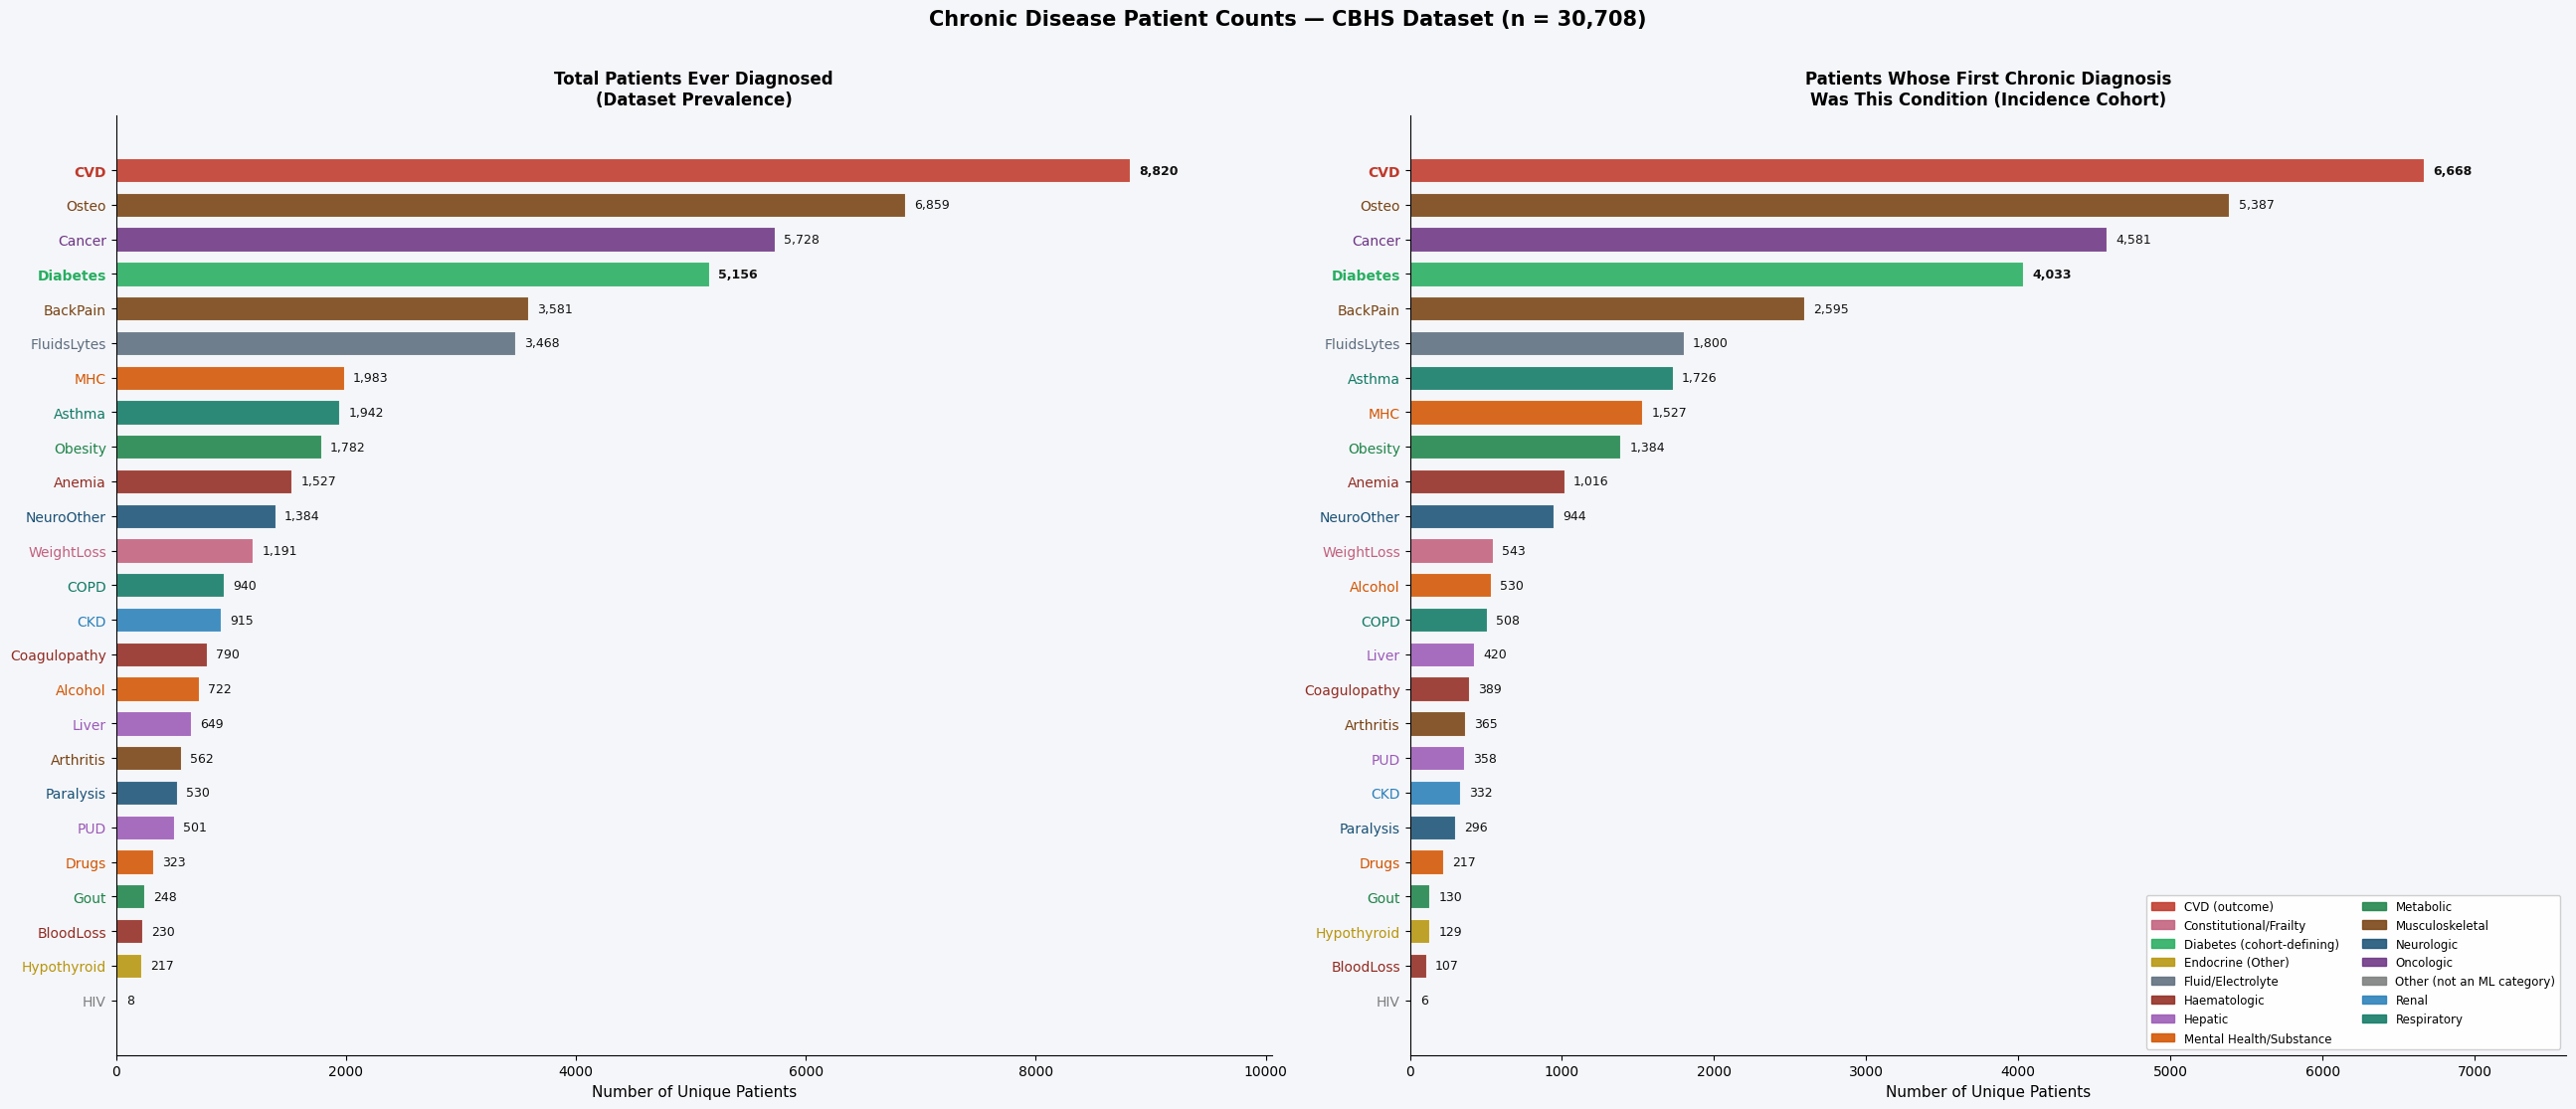

Bar charts saved.


In [3]:
# ── Side-by-side bar charts ───────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(26, 11))
fig.patch.set_facecolor('#f5f6fa')
fig.suptitle('Chronic Disease Patient Counts — CBHS Dataset (n = 30,708)',
             fontsize=15, fontweight='bold', y=1.01)

datasets = [
    (n_ever,       'Total Patients Ever Diagnosed\n(Dataset Prevalence)',  'n_ever'),
    (first_cohort, 'Patients Whose First Chronic Diagnosis\nWas This Condition (Incidence Cohort)', 'first_cohort'),
]

for ax, (data, title, key) in zip(axes, datasets):
    ax.set_facecolor('#f5f6fa')
    sorted_c  = sorted(ALL_CONDS, key=lambda c: data.get(c, 0))
    counts    = [data.get(c, 0) for c in sorted_c]
    colours   = [COND_COL.get(c, '#777') for c in sorted_c]

    bars = ax.barh(sorted_c, counts, color=colours, alpha=0.88, height=0.7,
                   edgecolor='white', linewidth=0.8)
    for bar, n, cond in zip(bars, counts, sorted_c):
        ax.text(bar.get_width() + max(counts)*0.009,
                bar.get_y() + bar.get_height()/2,
                f'{n:,}', va='center', ha='left', fontsize=9,
                fontweight='bold' if cond in ('Diabetes','CVD') else 'normal',
                color='#111')

    ax.set_xlabel('Number of Unique Patients', fontsize=11)
    ax.set_title(title, fontsize=12, fontweight='bold', pad=8)
    ax.spines[['top','right']].set_visible(False)
    ax.set_xlim(0, max(counts) * 1.14)
    ax.tick_params(labelsize=10)
    for tick, cond in zip(ax.get_yticklabels(), sorted_c):
        tick.set_color(COND_COL.get(cond, '#333'))
        tick.set_fontweight('bold' if cond in ('Diabetes','CVD') else 'normal')

# Shared legend
cat_seen = {}
for c, (cat, col) in COND_CATEGORY.items(): cat_seen.setdefault(cat, col)
leg = [mpatches.Patch(color=col, label=cat, alpha=0.88) for cat, col in sorted(cat_seen.items())]
axes[1].legend(handles=leg, fontsize=8.5, framealpha=0.92, edgecolor='#ccc',
               loc='lower right', ncol=2)

plt.tight_layout()
plt.savefig(BASE / 'bar_patients_per_condition.png', dpi=150,
            bbox_inches='tight', facecolor='#f5f6fa')
plt.show()
print('Bar charts saved.')

In [ ]:
# ── Build transition counts ────────────────────────────────────────────────────
# A direct transition A→B exists when: condition A is patient's most recent
# chronic diagnosis and B is their very next chronic diagnosis 

direct_trans = defaultdict(int)
concurrent   = defaultdict(int)

for pid, cond_dates in patient_cond_dates.items():
    valid = sorted([(c,d) for c,d in cond_dates.items() if pd.notna(d)], key=lambda x: x[1])
    if not valid: continue
    groups, cur_date, cur_group = [], None, []
    for cond, date in valid:
        if date == cur_date: cur_group.append(cond)
        else:
            if cur_group: groups.append(cur_group)
            cur_date, cur_group = date, [cond]
    if cur_group: groups.append(cur_group)
    for i, group in enumerate(groups):
        for c1, c2 in combinations(group, 2):
            concurrent[frozenset([c1, c2])] += 1
        if i + 1 < len(groups):
            for cf in group:
                for ct in groups[i+1]:
                    direct_trans[(cf, ct)] += 1

MIN_DIRECT = 20
DIR_FILT   = {k: v for k, v in direct_trans.items() if v >= MIN_DIRECT}
total_from = defaultdict(int)
total_to   = defaultdict(int)
for (a, b), cnt in direct_trans.items():
    total_from[a] += cnt; total_to[b] += cnt
TOTAL_TRANS = sum(direct_trans.values())

print(f'Total directed transitions : {TOTAL_TRANS:,}')
print(f'Unique directed edges      : {len(direct_trans):,}')
print(f'Filtered edges (n≥{MIN_DIRECT})    : {len(DIR_FILT)}')

# ── Statistical tests ────────────────────────────────────────────────────────────
def sig_label(p):
    if p < 0.001: return '***'
    if p < 0.01:  return '**'
    if p < 0.05:  return '*'
    return 'ns'

# One-sample t-test: H0: P(next=B | had A) = baseline P(B)
p_B_base = {b: total_to.get(b,0)/TOTAL_TRANS for b in ALL_CONDS}
TTEST = {}
for (a, b) in DIR_FILT:
    outcomes = [1 if b in patient_next[pid].get(a, set()) else 0
                for pid in patient_next if a in patient_next[pid] and patient_next[pid][a]]
    arr = np.array(outcomes, dtype=float)
    if len(arr) < 5 or arr.std() < 1e-10: continue
    t, p = ttest_1samp(arr, popmean=p_B_base.get(b, 0))
    TTEST[(a,b)] = {'t': t, 'p': p, 'sig': sig_label(p), 'n': len(arr), 'obs': arr.mean()}

# Chi-squared independence test (2x2 contingency table)
CHI2 = {}
for (a, b), n_ab in DIR_FILT.items():
    n_a_oth  = total_from.get(a,0) - n_ab
    n_nb     = max(total_to.get(b,0) - n_ab, 0)
    n_rest   = max(TOTAL_TRANS - n_ab - n_a_oth - n_nb, 0)
    try:
        chi2, p, _, _ = chi2_contingency([[n_ab, max(n_a_oth,0)], [n_nb, n_rest]], correction=False)
        CHI2[(a,b)] = {'chi2': chi2, 'p': p, 'sig': sig_label(p)}
    except: pass

# Directional Rate Ratio: RR_dir(A→B) = rate(A→B) / rate(B→A)
RR_DIR = {}
for (a, b), n_ab in DIR_FILT.items():
    n_ba = direct_trans.get((b, a), 0)
    N_a, N_b = first_cohort.get(a,0), first_cohort.get(b,0)
    if N_a == 0 or N_b == 0 or n_ba == 0: continue
    rate_ab, rate_ba = n_ab/N_a, n_ba/N_b
    rr = rate_ab / rate_ba
    tbl = [[n_ab, N_a-n_ab], [n_ba, N_b-n_ba]]
    try:
        _, p = fisher_exact(tbl) if min(n_ab,n_ba)<5 else (None, chi2_contingency(tbl, correction=False)[1])
    except: p = 1.0
    RR_DIR[(a,b)] = {'rr': rr, 'p': p, 'sig': sig_label(p),
                     'rate_ab': rate_ab*100, 'rate_ba': rate_ba*100, 'n_ab': n_ab, 'N_a': N_a}

n_sig_chi2  = sum(1 for s in CHI2.values()  if s['sig'] != 'ns')
n_sig_ttest = sum(1 for s in TTEST.values() if s['sig'] != 'ns')
n_sig_rr    = sum(1 for s in RR_DIR.values() if s['sig'] != 'ns')
print(f'Chi-squared: {len(CHI2)} edges, {n_sig_chi2} significant (p<0.05)')
print(f'T-test:      {len(TTEST)} edges, {n_sig_ttest} significant')
print(f'RR_dir:      {len(RR_DIR)} edges, {n_sig_rr} significant')

Total directed transitions : 17,192
Unique directed edges      : 535
Filtered edges (n≥20)    : 206


Chi-squared: 206 edges, 98 significant (p<0.05)
T-test:      206 edges, 109 significant
RR_dir:      206 edges, 174 significant


## 2. Network Centrality Measures

Six centrality metrics on the directed, weighted (transition-count) network: in/out-degree, betweenness, closeness, PageRank, eigenvector.

In [5]:
# ── Build graph and compute all centrality metrics ────────────────────────────
G_w = nx.DiGraph()
G_w.add_nodes_from(ALL_CONDS)
for (a, b), cnt in DIR_FILT.items():
    G_w.add_edge(a, b, weight=cnt)

# Global metrics
density   = nx.density(G_w)
recip     = nx.overall_reciprocity(G_w)
scc       = list(nx.strongly_connected_components(G_w))
wcc       = list(nx.weakly_connected_components(G_w))
large_scc = max(scc, key=len)
G_scc     = G_w.subgraph(large_scc).copy()
avg_path  = nx.average_shortest_path_length(G_scc)
diameter  = nx.diameter(G_scc)

print('GLOBAL NETWORK METRICS')
print('=' * 52)
print(f'  Nodes                          : {G_w.number_of_nodes()}')
print(f'  Directed edges (n≥{MIN_DIRECT})         : {G_w.number_of_edges()}')
print(f'  Density                        : {density:.4f}  ({density*100:.1f}% of possible edges)')
print(f'  Reciprocity                    : {recip:.4f}  ({recip*100:.0f}% of edges have a reverse)')
print(f'  Strongly connected components  : {len(scc)}')
print(f'  Largest SCC size               : {len(large_scc)} conditions')
print(f'  Weakly connected components    : {len(wcc)}')
print(f'  Avg. path length (largest SCC) : {avg_path:.3f} hops')
print(f'  Diameter (largest SCC)         : {diameter} hops')
print()

# Node metrics
in_deg   = dict(G_w.in_degree())
out_deg  = dict(G_w.out_degree())
in_str   = dict(G_w.in_degree(weight='weight'))
out_str  = dict(G_w.out_degree(weight='weight'))
between  = nx.betweenness_centrality(G_w, weight='weight', normalized=True)
close    = nx.closeness_centrality(G_w)
pr       = nx.pagerank(G_w, weight='weight')
try:
    eigen = nx.eigenvector_centrality(G_w, weight='weight', max_iter=500)
except nx.PowerIterationFailedConvergence:
    eigen = {c: float('nan') for c in ALL_CONDS}
edge_bet = nx.edge_betweenness_centrality(G_w, weight='weight', normalized=True)

metric_df = pd.DataFrame({
    'condition':    ALL_CONDS,
    'n_ever':       [n_ever[c]             for c in ALL_CONDS],
    'first_cohort': [first_cohort.get(c,0) for c in ALL_CONDS],
    'in_degree':    [in_deg.get(c,0)       for c in ALL_CONDS],
    'out_degree':   [out_deg.get(c,0)      for c in ALL_CONDS],
    'in_strength':  [in_str.get(c,0)       for c in ALL_CONDS],
    'out_strength': [out_str.get(c,0)      for c in ALL_CONDS],
    'betweenness':  [between.get(c,0)      for c in ALL_CONDS],
    'closeness':    [close.get(c,0)        for c in ALL_CONDS],
    'pagerank':     [pr.get(c,0)           for c in ALL_CONDS],
    'eigenvector':  [eigen.get(c,float('nan')) for c in ALL_CONDS],
}).sort_values('betweenness', ascending=False).reset_index(drop=True)

print('NODE CENTRALITY METRICS (sorted by betweenness)')
print('=' * 120)
print(f'  {"Condition":<14}  {"In-deg":>6}  {"Out-deg":>7}  {"In-str":>7}  {"Out-str":>8}'
      f'  {"Betweenness":>12}  {"Closeness":>10}  {"PageRank":>9}  {"Eigenvec":>9}  {"n_ever":>8}')
print('-' * 120)
for _, row in metric_df.iterrows():
    marker = ' ◄' if row.condition in ('Diabetes','CVD') else ''
    ev = f'{row.eigenvector:.4f}' if not pd.isna(row.eigenvector) else '  n/a '
    print(f'  {row.condition:<14}  {row.in_degree:>6.0f}  {row.out_degree:>7.0f}'
          f'  {row.in_strength:>7.0f}  {row.out_strength:>8.0f}'
          f'  {row.betweenness:>12.5f}  {row.closeness:>10.4f}'
          f'  {row.pagerank:>9.5f}  {ev:>9}  {row.n_ever:>8,}{marker}')

metric_df.to_csv(BASE / 'centrality_metrics.csv', index=False)
print('\nSaved → centrality_metrics.csv')

GLOBAL NETWORK METRICS
  Nodes                          : 25
  Directed edges (n≥20)         : 206
  Density                        : 0.3433  (34.3% of possible edges)
  Reciprocity                    : 0.8447  (84% of edges have a reverse)
  Strongly connected components  : 5
  Largest SCC size               : 21 conditions
  Weakly connected components    : 2
  Avg. path length (largest SCC) : 1.562 hops
  Diameter (largest SCC)         : 3 hops

NODE CENTRALITY METRICS (sorted by betweenness)
  Condition       In-deg  Out-deg   In-str   Out-str   Betweenness   Closeness   PageRank   Eigenvec    n_ever
------------------------------------------------------------------------------------------------------------------------
  MHC                 12       12      487       529       0.11594      0.5952    0.04280     0.0994     1,983
  Osteo               17       18     1670      1917       0.10507      0.7246    0.09326     0.3867     6,859
  Cancer              14       18     1249   

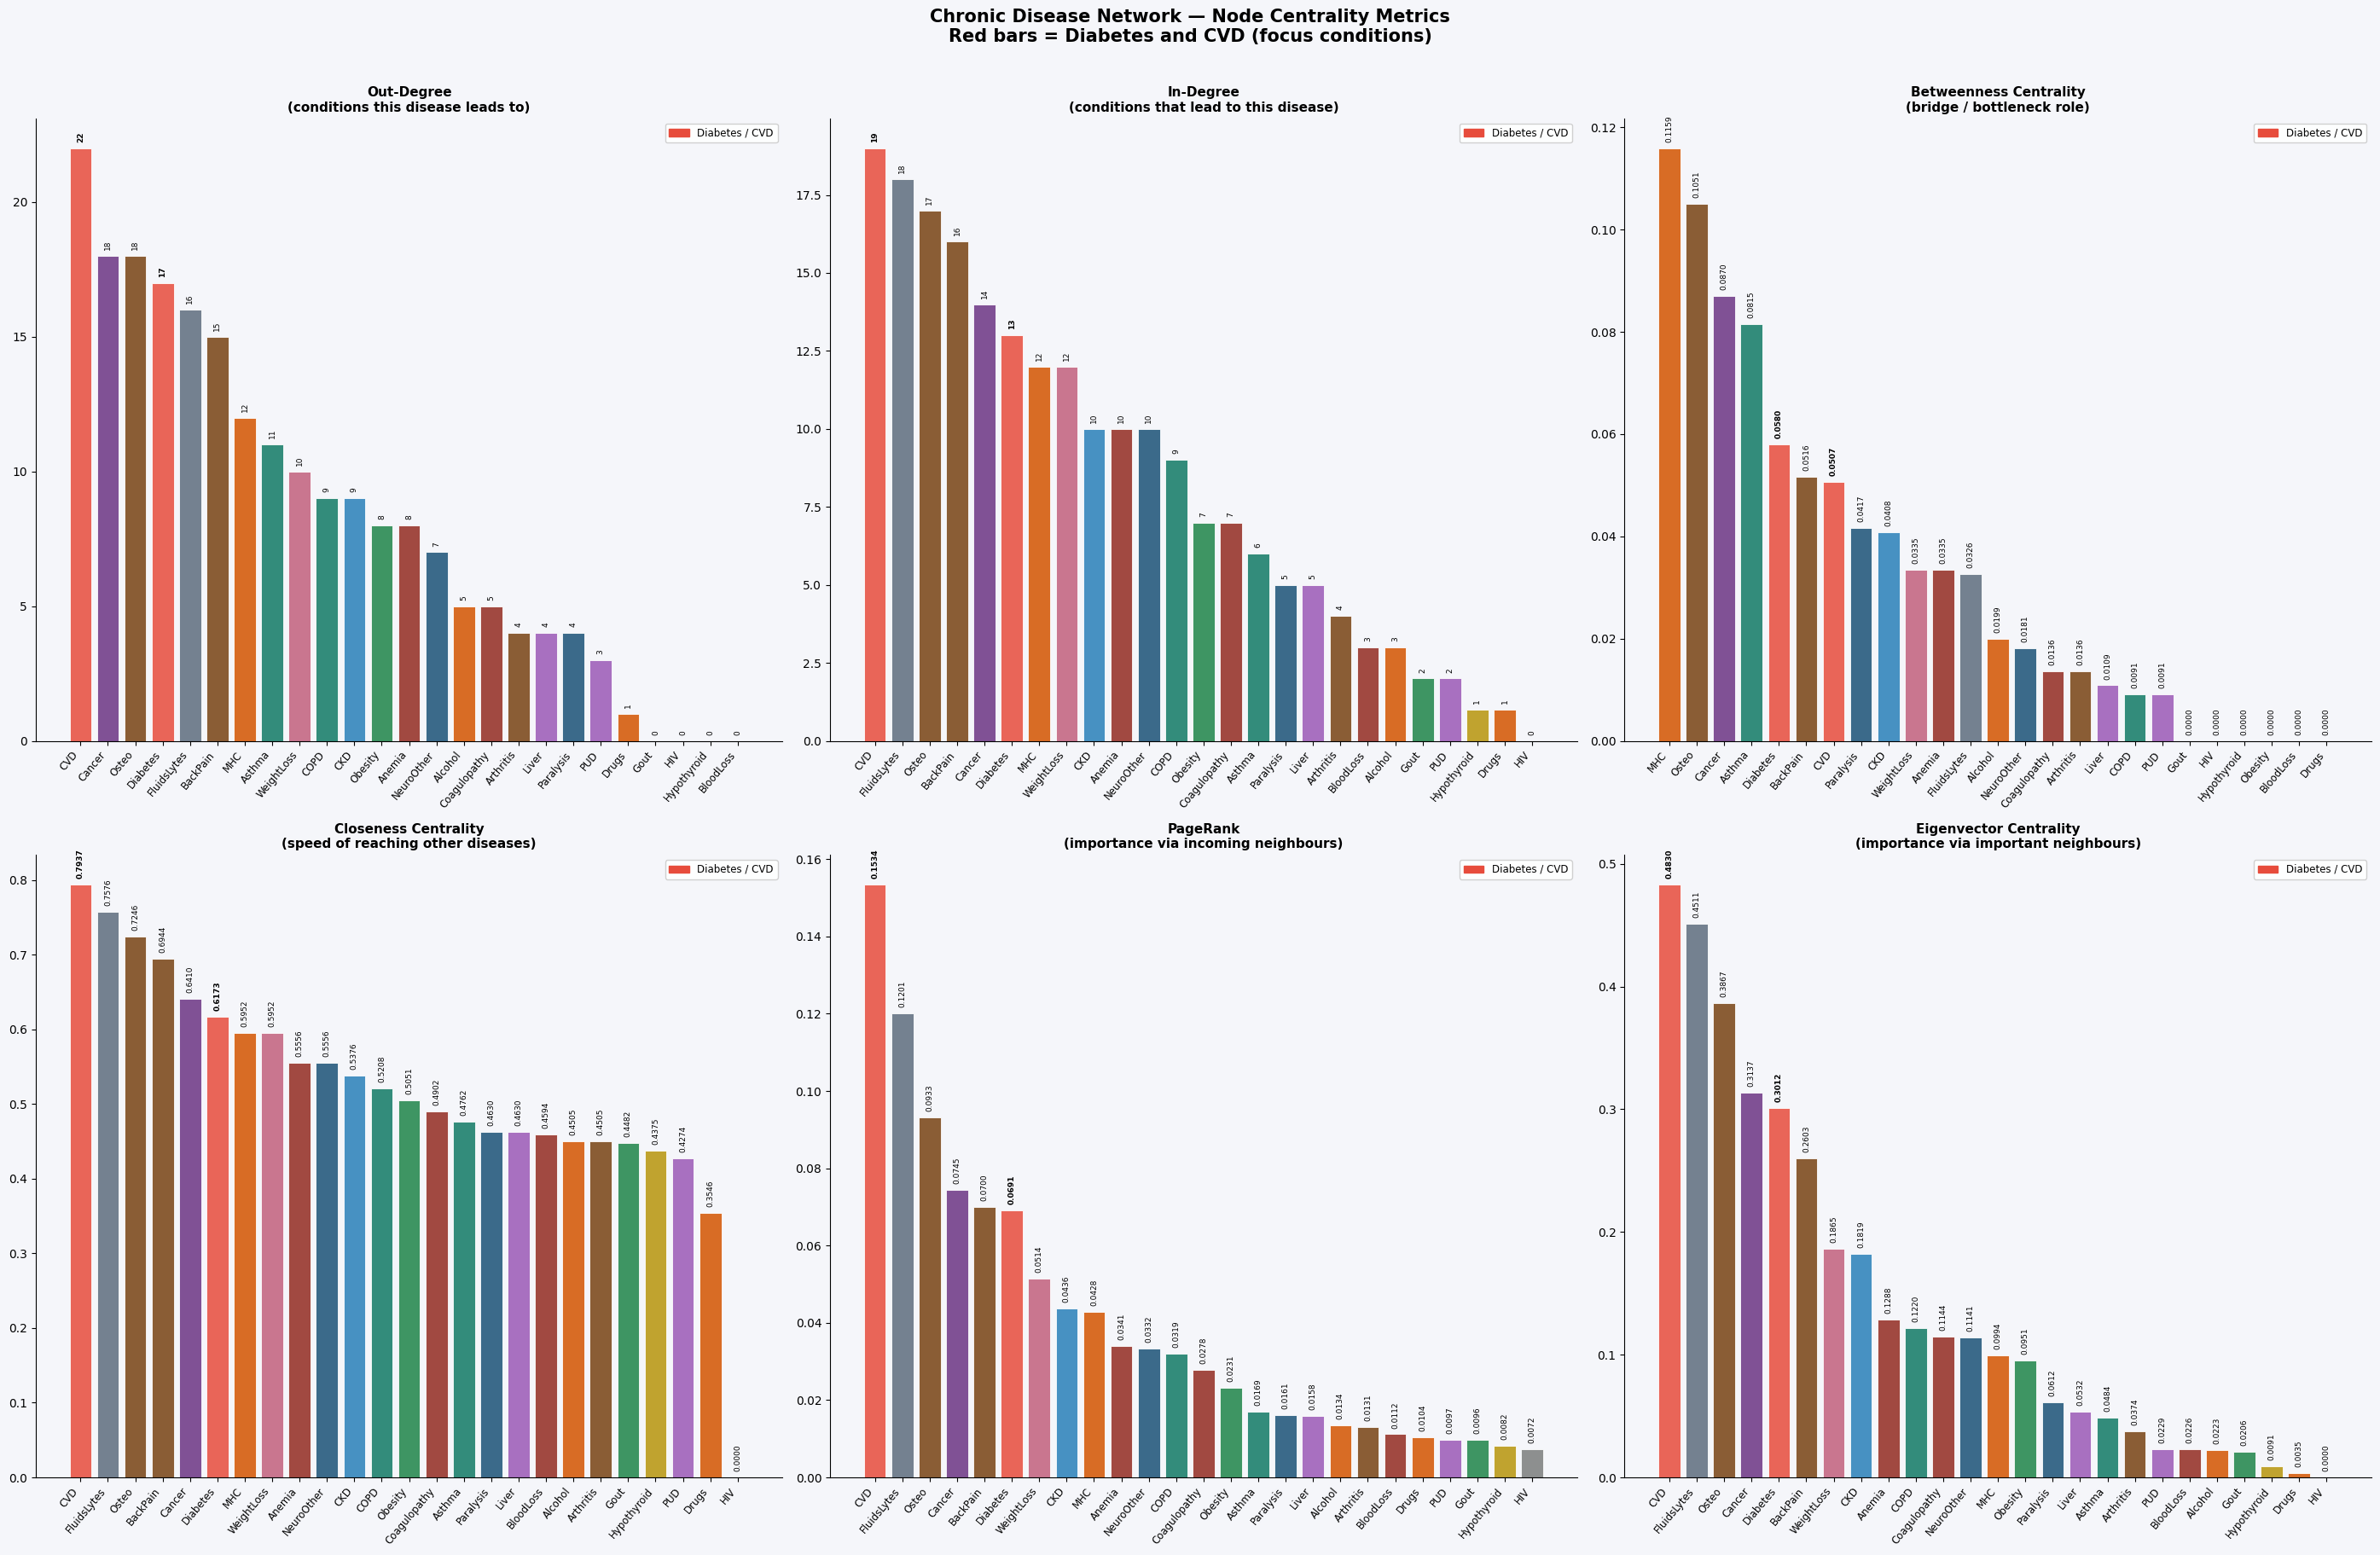

Centrality chart saved.


In [6]:
# ── Centrality metric visualisations ─────────────────────────────────────────
HIGHLIGHT = {'Diabetes', 'CVD'}
HIGHLIGHT_COL = '#e74c3c'

fig, axes = plt.subplots(2, 3, figsize=(28, 18))
fig.patch.set_facecolor('#f5f6fa')
fig.suptitle('Chronic Disease Network — Node Centrality Metrics\n'
             'Red bars = Diabetes and CVD (focus conditions)',
             fontsize=15, fontweight='bold', y=1.01)

panel_specs = [
    ('out_degree',  'Out-Degree\n(conditions this disease leads to)'),
    ('in_degree',   'In-Degree\n(conditions that lead to this disease)'),
    ('betweenness', 'Betweenness Centrality\n(bridge / bottleneck role)'),
    ('closeness',   'Closeness Centrality\n(speed of reaching other diseases)'),
    ('pagerank',    'PageRank\n(importance via incoming neighbours)'),
    ('eigenvector', 'Eigenvector Centrality\n(importance via important neighbours)'),
]

for ax, (col, title) in zip(axes.flatten(), panel_specs):
    ax.set_facecolor('#f5f6fa')
    df_s   = metric_df.sort_values(col, ascending=False).dropna(subset=[col])
    conds  = df_s['condition'].tolist()
    vals   = df_s[col].tolist()
    colors = [HIGHLIGHT_COL if c in HIGHLIGHT else COND_COL.get(c, '#888') for c in conds]

    bars = ax.bar(range(len(conds)), vals, color=colors, alpha=0.85,
                  edgecolor='white', linewidth=0.7)
    ax.set_xticks(range(len(conds)))
    ax.set_xticklabels(conds, rotation=50, ha='right', fontsize=8.5)
    ax.set_title(title, fontsize=11, fontweight='bold', pad=6)
    ax.spines[['top','right']].set_visible(False)
    ax.set_facecolor('#f5f6fa')

    fmt = '.4f' if col in ('betweenness','closeness','pagerank','eigenvector') else '.0f'
    for bar, v, c in zip(bars, vals, conds):
        if pd.isna(v): continue
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + max(v for v in vals if not pd.isna(v))*0.01,
                f'{v:{fmt}}', ha='center', va='bottom', fontsize=6.5,
                fontweight='bold' if c in HIGHLIGHT else 'normal', rotation=90)

    # Highlight legend
    highlight_handle = mpatches.Patch(color=HIGHLIGHT_COL, label='Diabetes / CVD')
    ax.legend(handles=[highlight_handle], fontsize=8.5, loc='upper right', framealpha=0.9)

plt.tight_layout()
plt.savefig(BASE / 'centrality_metrics_chart.png', dpi=150,
            bbox_inches='tight', facecolor='#f5f6fa')
plt.show()
print('Centrality chart saved.')

## 3. Transition Rate Analysis -- Justification for Diabetes to CVD

Rate(A to B) = n_direct(A to B) / n_first_cohort(A). RR_dir(A to B) = Rate(A to B) / Rate(B to A), tested via chi-squared/Fisher exact on the 2x2 table.

In [7]:
# ── Full Diabetes ego transition table ────────────────────────────────────────
diab_rows = []
for b in ALL_CONDS:
    if b == 'Diabetes': continue
    n_ab = direct_trans.get(('Diabetes', b), 0)
    N_a  = first_cohort.get('Diabetes', 1)
    rate = n_ab / N_a * 100
    rr_s = RR_DIR.get(('Diabetes', b), {})
    tt_s = TTEST.get(('Diabetes', b), {})
    ch_s = CHI2.get(('Diabetes', b), {})
    n_conc = concurrent.get(frozenset(['Diabetes', b]), 0)
    diab_rows.append({
        'To condition':   b,
        'n_direct':       n_ab,
        'Rate % (Diab→X)':f'{rate:.2f}%',
        'n_concurrent':   n_conc,
        'RR_dir':         f'{rr_s["rr"]:.2f}' if rr_s else '—',
        'RR_p':           f'{rr_s["p"]:.2e}'  if rr_s else '—',
        'RR_sig':         rr_s.get('sig','—'),
        't_stat':         f'{tt_s["t"]:.2f}'  if tt_s else '—',
        't_sig':          tt_s.get('sig','—'),
        'chi2':           f'{ch_s["chi2"]:.1f}' if ch_s else '—',
        'chi2_sig':       ch_s.get('sig','—'),
        '_rate_num':      rate,
    })

diab_df = pd.DataFrame(diab_rows).sort_values('_rate_num', ascending=False).drop('_rate_num', axis=1)
print(f'DIABETES FIRST-COHORT: n = {first_cohort.get("Diabetes",0):,} patients')
print('All transitions ranked by rate (% of cohort directly transitioning to each condition)')
print('=' * 108)
print(diab_df.to_string(index=False))
diab_df.to_csv(BASE / 'diabetes_ego_transitions.csv', index=False)
print('\nSaved → diabetes_ego_transitions.csv')

# ── Cross-network top rates table ──────────────────────────────────────────────
print()
print('TOP TRANSITION RATES ACROSS ENTIRE NETWORK')
print('(edges with first_cohort ≥ 500 to ensure statistical stability)')
print('=' * 90)
all_rates = []
for (a, b), cnt in DIR_FILT.items():
    N_a = first_cohort.get(a, 0)
    if N_a < 500: continue
    rate = cnt / N_a * 100
    rr_s = RR_DIR.get((a, b), {})
    ch_s = CHI2.get((a, b), {})
    all_rates.append({'Edge': f'{a}→{b}', 'n_first_cohort_A': N_a,
                      'n_direct': cnt, 'Rate%': rate,
                      'RR_dir': rr_s.get('rr', float('nan')),
                      'RR_sig': rr_s.get('sig','—'),
                      'chi2_sig': ch_s.get('sig','—')})

rates_df = pd.DataFrame(all_rates).sort_values('Rate%', ascending=False).head(20)
print(rates_df.to_string(index=False, float_format='%.2f'))

DIABETES FIRST-COHORT: n = 4,033 patients
All transitions ranked by rate (% of cohort directly transitioning to each condition)
To condition  n_direct Rate % (Diab→X)  n_concurrent RR_dir     RR_p RR_sig t_stat t_sig chi2 chi2_sig
         CVD       387           9.60%           642   1.70 1.27e-14    ***  10.41   *** 78.4      ***
 FluidsLytes       218           5.41%           180   1.57 1.21e-03     **   3.11    **  0.0       ns
      Cancer       170           4.22%           197   1.30 1.56e-02      *   4.46   ***  6.3        *
       Osteo       169           4.19%           231   0.94 5.61e-01     ns   1.87    ns  1.0       ns
    BackPain       129           3.20%           112   1.00 1.00e+00     ns   2.56     *  0.1       ns
         CKD       118           2.93%           100   0.32 3.36e-09    ***   5.12   *** 21.1      ***
     Obesity        83           2.06%           151   0.41 1.27e-08    ***   4.88   *** 26.7      ***
      Anemia        80           1.98%          

## 4. Statistically Validated Circular Transition Network

Only chi-squared-significant edges (p < 0.05) are drawn; edge width = RR_dir, opacity = transition rate, colour = source condition's category.

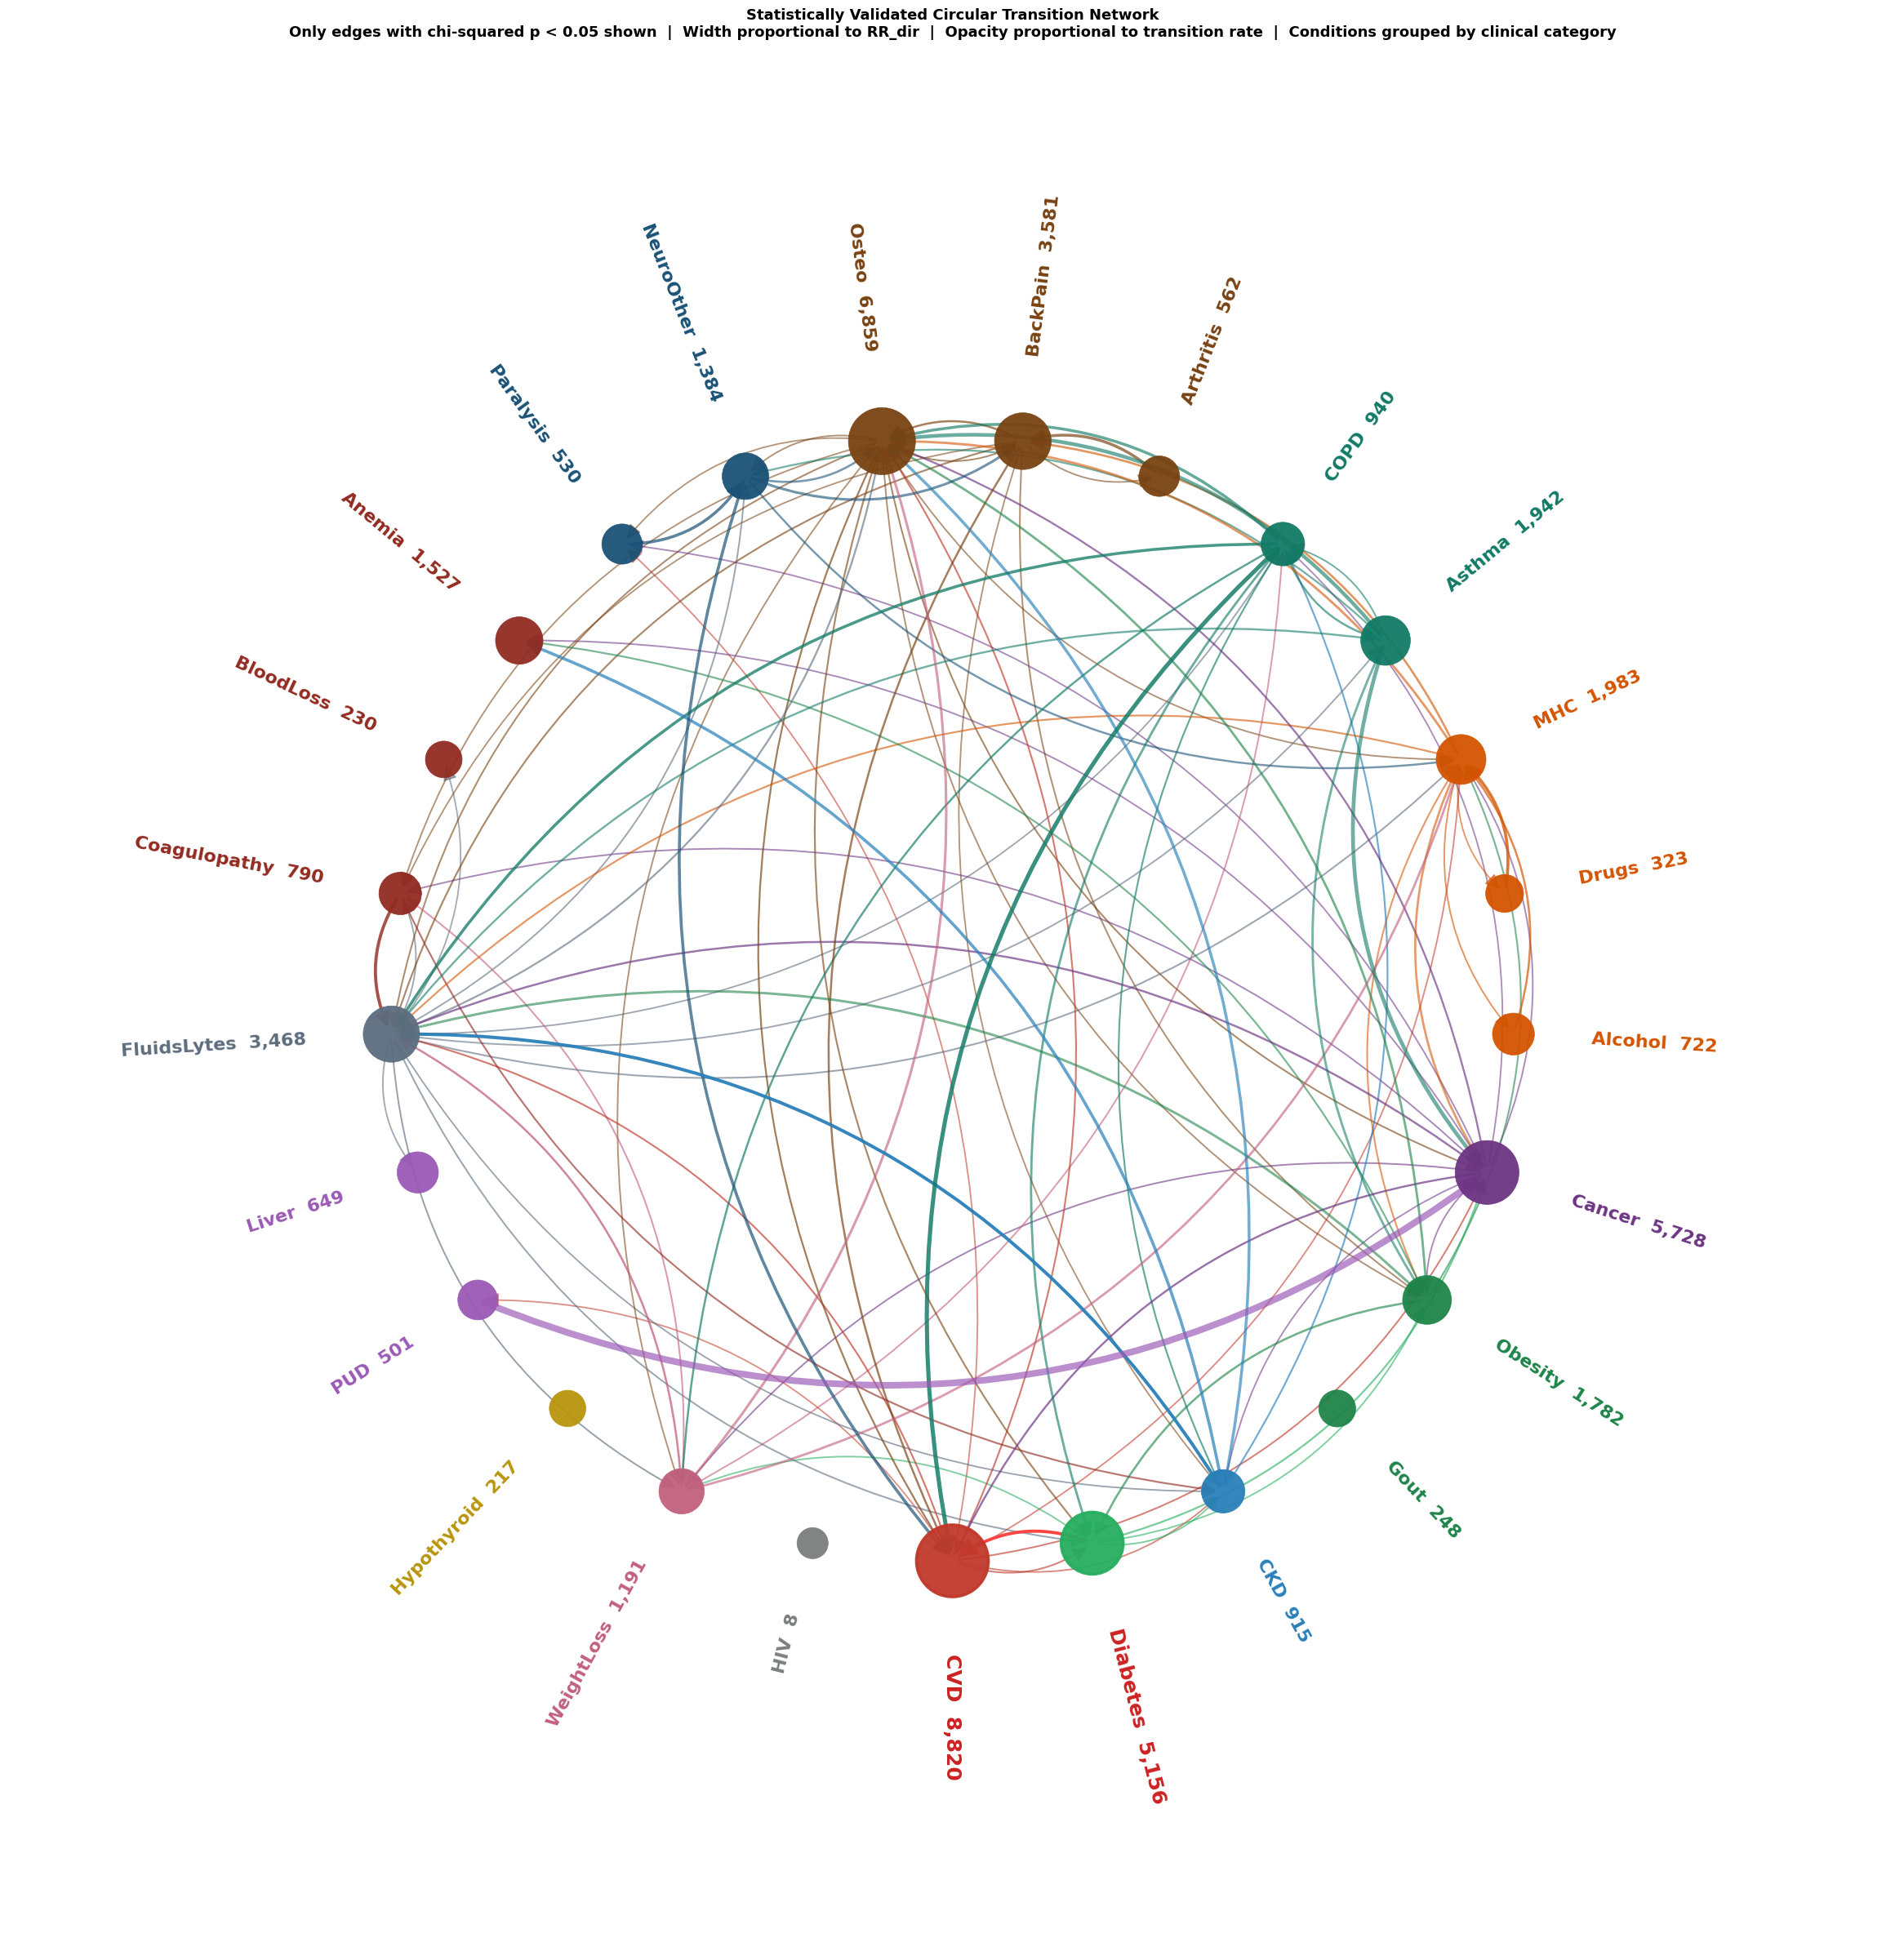

Circular network: 98 statistically validated edges shown, 25 nodes grouped into 15 categories.


In [ ]:
CATEGORY_ORDER = ['CVD (outcome)', 'Diabetes (cohort-defining)', 'Renal', 'Metabolic',
                   'Oncologic', 'Mental Health/Substance', 'Respiratory', 'Musculoskeletal',
                   'Neurologic', 'Haematologic', 'Fluid/Electrolyte', 'Hepatic',
                   'Endocrine (Other)', 'Constitutional/Frailty', 'Other (not an ML category)']
cond_by_cat = defaultdict(list)
for c in ALL_CONDS:
    cond_by_cat[COND_CATEGORY.get(c, ('Other', '#777'))[0]].append(c)
circ_order = [c for cat in CATEGORY_ORDER for c in sorted(cond_by_cat.get(cat, []))]
assert set(circ_order) == set(ALL_CONDS)

angles_c = np.linspace(0, 2*np.pi, len(circ_order), endpoint=False)

RING_R = 1.28
pos_c  = {c: np.array([RING_R*np.cos(a-np.pi/2), RING_R*np.sin(a-np.pi/2)])
          for c, a in zip(circ_order, angles_c)}

# Only validated edges (chi2 p<0.05)
CIRC_EDGES = {(a, b): cnt for (a, b), cnt in DIR_FILT.items()
              if CHI2.get((a, b), {}).get('p', 1) < 0.05}

max_rr   = max((RR_DIR[k]['rr'] for k in CIRC_EDGES if k in RR_DIR), default=3)
max_rate = max((cnt / first_cohort.get(a, 1) * 100 for (a, b), cnt in CIRC_EDGES.items()
                if first_cohort.get(a, 0) > 0), default=10)

def edge_width(a, b, cnt):
    if (a, b) in RR_DIR:
        return 1.3 + 4.5 * min(RR_DIR[(a, b)]['rr'], max_rr) / max_rr
    rate = cnt / first_cohort.get(a, 1) * 100
    return 1.3 + 4.5 * rate / max_rate

def edge_alpha(a, b, cnt):
    rate = cnt / first_cohort.get(a, 1) * 100
    return min(0.55 + 0.4 * rate / max_rate, 0.95)

fig, ax = plt.subplots(figsize=(24, 24))
fig.patch.set_facecolor('white')
ax.set_facecolor('white')

sorted_edges = sorted(CIRC_EDGES.items(),
                      key=lambda x: RR_DIR.get(x[0], {}).get('rr', 0))
for (a, b), cnt in sorted_edges:
    pa, pb = pos_c[a], pos_c[b]
    lw     = edge_width(a, b, cnt)
    alpha  = edge_alpha(a, b, cnt)
    color  = COND_COL.get(a, '#888')
    is_key = (a == 'Diabetes' and b == 'CVD')
    ax.annotate('', xy=pb, xytext=pa,
        arrowprops=dict(
            arrowstyle='-|>', mutation_scale=32 if is_key else 26,
            connectionstyle='arc3,rad=0.28',
            color='#ff4444' if is_key else color,
            lw=lw * 1.6 if is_key else lw, alpha=1.0 if is_key else alpha,
            shrinkA=6, shrinkB=6, capstyle='round'),
        annotation_clip=False, zorder=4 if is_key else 2)

_max_np = max(n_ever.values(), default=1)
for c, a in zip(circ_order, angles_c):
    p     = pos_c[c]
    color = COND_COL.get(c, '#777')
    nr    = 0.034 + 0.048 * np.sqrt(n_ever.get(c, 0) / _max_np)
    is_focus = c in ('Diabetes', 'CVD')
    ax.add_patch(plt.Circle(p, nr, color=color, zorder=5, alpha=0.95,
                            linewidth=2.5 if is_focus else 0.5,
                            edgecolor='#ff4444' if is_focus else color))

    lx = (RING_R + nr + 0.13) * np.cos(a - np.pi/2)
    ly = (RING_R + nr + 0.13) * np.sin(a - np.pi/2)
    deg = np.degrees(a - np.pi/2)
    ha, rot = ('left', deg) if -90 <= deg <= 90 else ('right', deg + 180)
    n_p = n_ever.get(c, 0)
    ax.text(lx, ly, f'{c}  {n_p:,}',
            fontsize=18 if is_focus else 16, ha=ha, va='center',
            color='#cc2222' if is_focus else color,
            fontweight='bold', rotation=rot, rotation_mode='anchor', zorder=6)

ax.set_xlim(-2.15, 2.15)
ax.set_ylim(-2.15, 2.15)
ax.set_aspect('equal')
ax.axis('off')
ax.set_title(
    'Statistically Validated Circular Transition Network\n'
    'Only edges with chi-squared p < 0.05 shown  |  Width proportional to RR_dir  |  Opacity proportional to transition rate  |  '
    'Conditions grouped by clinical category',
    fontsize=13, fontweight='bold', color='black', pad=16)

# Category legend (node/edge colour) + styling legend (what width/opacity/red mean)
cat_seen = {}
for cat in CATEGORY_ORDER:
    members = cond_by_cat.get(cat, [])
    if members:
        cat_seen[cat] = COND_COL[members[0]]
cat_handles = [mpatches.Patch(facecolor=col, edgecolor='white', label=cat) for cat, col in cat_seen.items()]

style_handles = [
    plt.Line2D([0], [0], color='#555', lw=1.2, alpha=0.4, label='Thin / faint: low RR_dir or low rate'),
    plt.Line2D([0], [0], color='#555', lw=5.5, alpha=0.9, label='Thick / solid: high RR_dir and high rate'),
    plt.Line2D([0], [0], color='#ff4444', lw=5.5, label='Diabetes to CVD (focus pathway)'),
]

plt.tight_layout()
plt.savefig(BASE / 'circular_network_validated.png', dpi=150,
            bbox_inches='tight', facecolor='white')
plt.show()
print(f'Circular network: {len(CIRC_EDGES)} statistically validated edges shown, {len(circ_order)} nodes grouped into {len(cat_seen)} categories.')

## 4b. Ego Networks: Diabetes and CVD in Focus

Significant neighbours only, per focus condition: 8 for Diabetes (5 out, 5 in), 11 for CVD (8 out, 6 in). Arrow colour encodes direction (teal = into, orange = out of); width = transition rate.

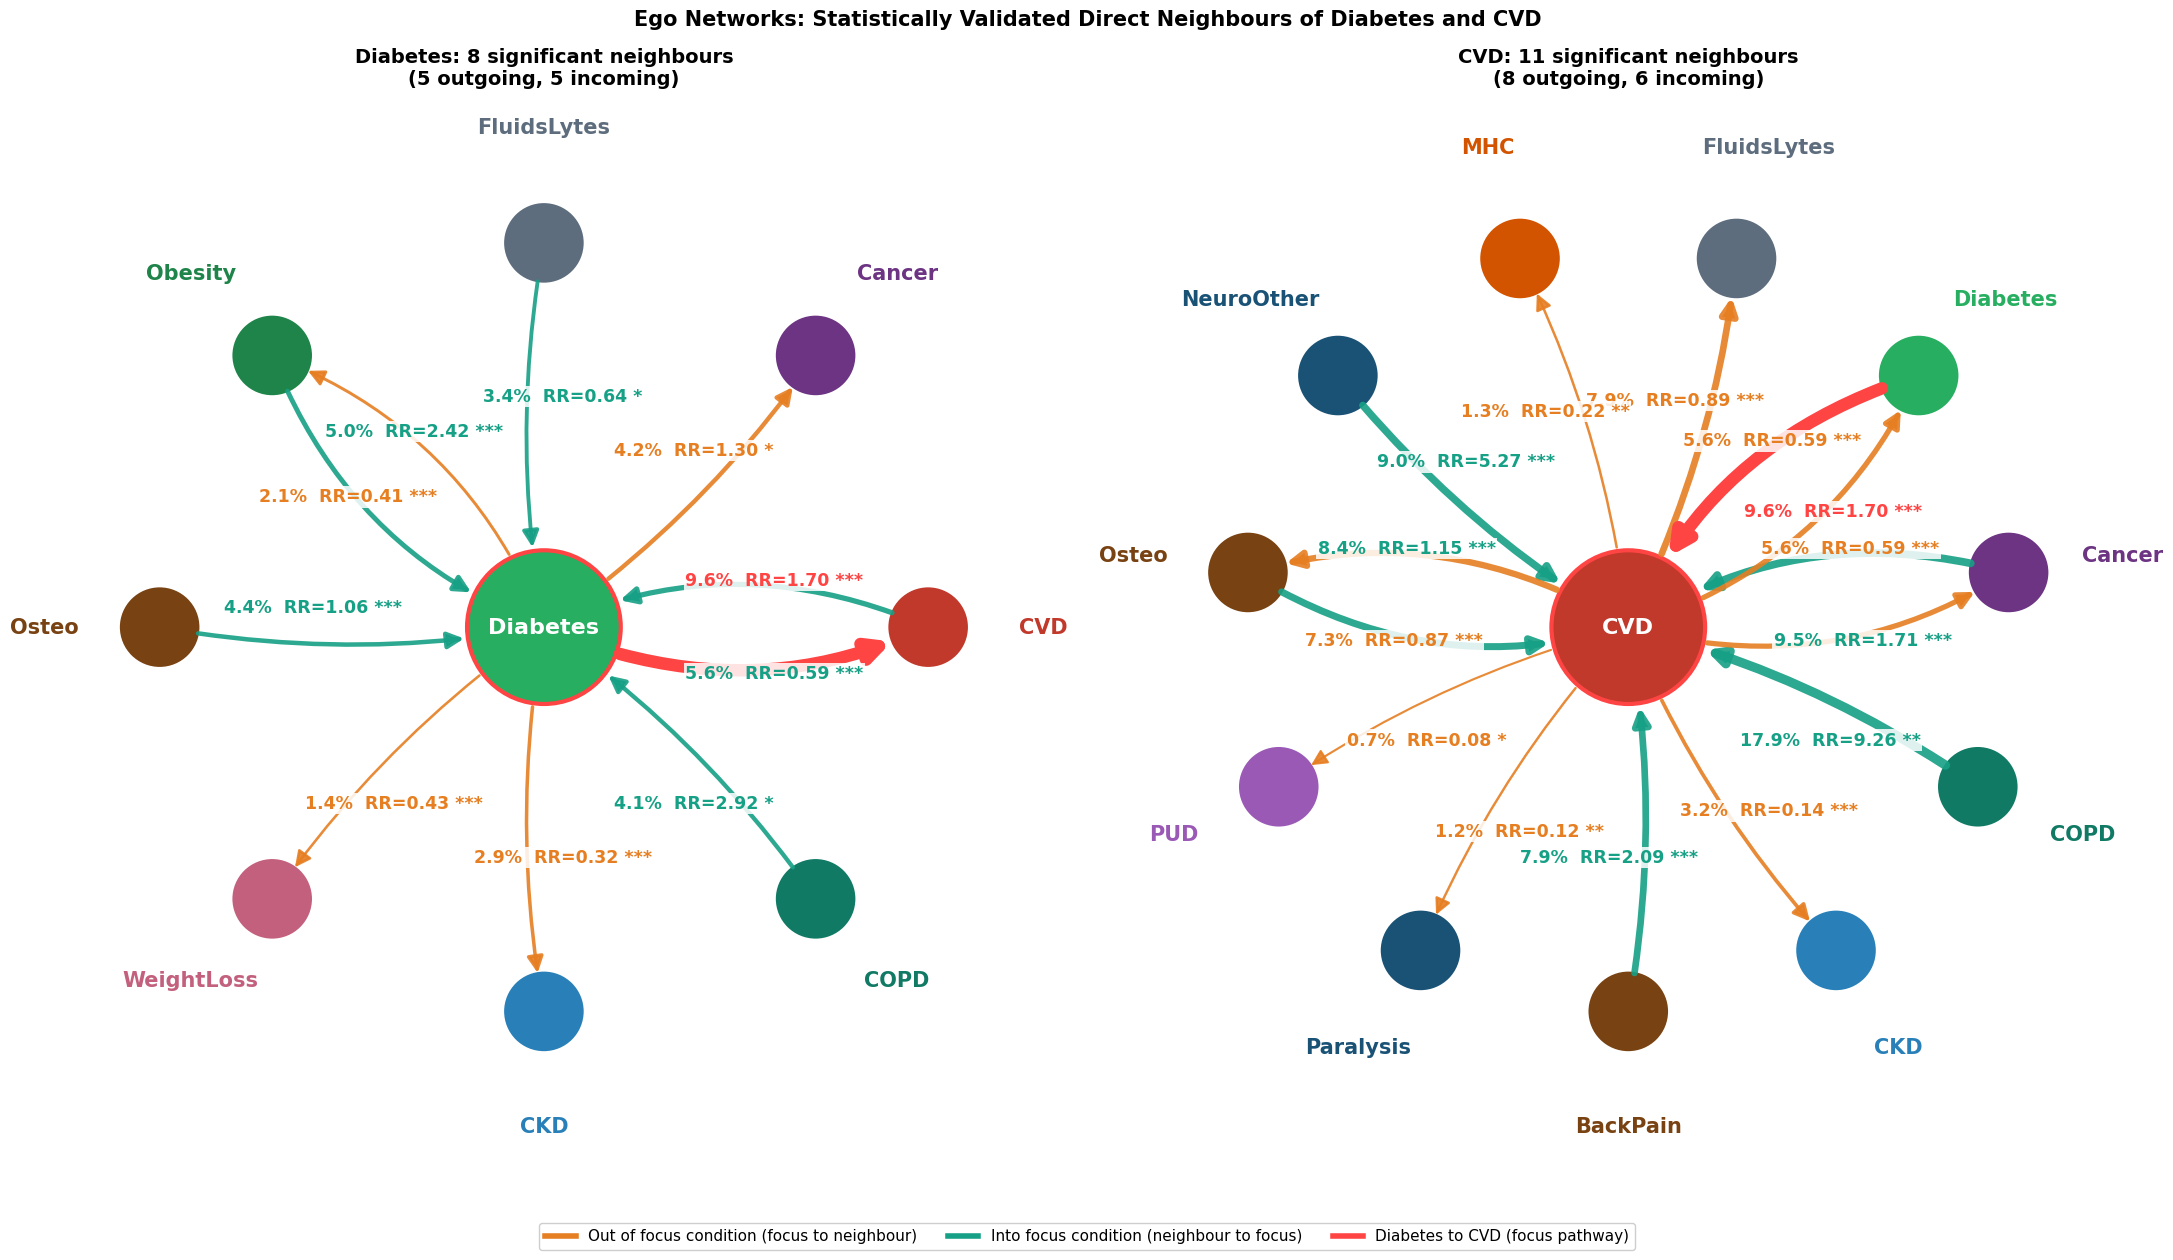

Ego networks saved -> ego_networks_diabetes_cvd.png


In [ ]:
# ── Ego networks: Diabetes and CVD, significant neighbours only ────────────────
IN_COLOR, OUT_COLOR, KEY_COLOR = '#16a085', '#e67e22', '#ff4444'

def ego_edges(center):
    """Significant (chi2 p<0.05) edges touching `center`, split by direction."""
    out_e = {(a, b): v for (a, b), v in CIRC_EDGES.items() if a == center}
    in_e  = {(a, b): v for (a, b), v in CIRC_EDGES.items() if b == center}
    return out_e, in_e

def label_box(ax, x, y, text, color):
    ax.text(x, y, text, fontsize=12.5, color=color, ha='center', va='center', fontweight='bold', zorder=10,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=1.3))

def draw_ego(ax, center):
    out_e, in_e = ego_edges(center)
    neighbours = sorted(set(b for (_, b) in out_e) | set(a for (a, _) in in_e))
    n = len(neighbours)
    angles = np.linspace(0, 2*np.pi, n, endpoint=False)
    R = 1.6
    npos = {nb: np.array([R*np.cos(a - np.pi/2), R*np.sin(a - np.pi/2)]) for nb, a in zip(neighbours, angles)}

    def edge_lw(rate):
        return 1.2 + 5.5 * min(rate / 12.0, 1.0)

    for nb in neighbours:
        both = (center, nb) in out_e and (nb, center) in in_e
        is_key_pair = {center, nb} == {'Diabetes', 'CVD'}
        rad = 0.22 if both else 0.09
        if (center, nb) in out_e:
            cnt = out_e[(center, nb)]
            rate = cnt / first_cohort.get(center, 1) * 100
            rr = RR_DIR.get((center, nb), {})
            ch = CHI2.get((center, nb), {})
            is_key = is_key_pair and center == 'Diabetes'
            ax.annotate('', xy=npos[nb], xytext=(0, 0),
                arrowprops=dict(arrowstyle='-|>', mutation_scale=30 if is_key else 24,
                                 connectionstyle=f'arc3,rad={rad}',
                                 color=KEY_COLOR if is_key else OUT_COLOR,
                                 lw=(edge_lw(rate) * 1.6) if is_key else edge_lw(rate),
                                 alpha=1.0 if is_key else 0.9, shrinkA=58, shrinkB=28, capstyle='round'),
                zorder=9 if is_key else 8)
            d = npos[nb]; perp = np.array([-d[1], d[0]]) / np.linalg.norm(d)
            mid = d * 0.60 + perp * (rad * np.linalg.norm(d) * 0.55)
            label_box(ax, mid[0], mid[1], f'{rate:.1f}%  RR={rr.get("rr", float("nan")):.2f} {ch.get("sig","")}',
                       KEY_COLOR if is_key else OUT_COLOR)
        if (nb, center) in in_e:
            cnt = in_e[(nb, center)]
            rate = cnt / first_cohort.get(nb, 1) * 100
            rr = RR_DIR.get((nb, center), {})
            ch = CHI2.get((nb, center), {})
            is_key = is_key_pair and center == 'CVD'
            ax.annotate('', xy=(0, 0), xytext=npos[nb],
                arrowprops=dict(arrowstyle='-|>', mutation_scale=30 if is_key else 24,
                                 connectionstyle=f'arc3,rad={rad}',
                                 color=KEY_COLOR if is_key else IN_COLOR,
                                 lw=(edge_lw(rate) * 1.6) if is_key else edge_lw(rate),
                                 alpha=1.0 if is_key else 0.9, shrinkA=28, shrinkB=58, capstyle='round'),
                zorder=9 if is_key else 8)
            d = npos[nb]; perp = np.array([-d[1], d[0]]) / np.linalg.norm(d)
            mid = d * 0.60 - perp * (rad * np.linalg.norm(d) * 0.55)
            label_box(ax, mid[0], mid[1], f'{rate:.1f}%  RR={rr.get("rr", float("nan")):.2f} {ch.get("sig","")}',
                       KEY_COLOR if is_key else IN_COLOR)

    for nb, a in zip(neighbours, angles):
        p = npos[nb]
        ax.add_patch(plt.Circle(p, 0.17, facecolor=COND_COL.get(nb, '#888'), edgecolor='white',
                                 linewidth=1.5, zorder=5))
        lx, ly = p * 1.30
        ax.text(lx, ly, nb, fontsize=15, ha='center', va='center', fontweight='bold',
                color=COND_COL.get(nb, '#333'), zorder=10)

    ax.add_patch(plt.Circle((0, 0), 0.32, facecolor=COND_COL.get(center, '#333'), edgecolor='#ff4444',
                             linewidth=3, zorder=5))
    ax.text(0, 0, center, fontsize=16, ha='center', va='center', fontweight='bold', color='white', zorder=10)

    lim = R + 0.6
    ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
    ax.set_aspect('equal'); ax.axis('off')
    ax.set_title(f'{center}: {n} significant neighbours\n'
                 f'({len(out_e)} outgoing, {len(in_e)} incoming)', fontsize=14, fontweight='bold', pad=10)

fig, axes = plt.subplots(1, 2, figsize=(22, 12))
fig.patch.set_facecolor('white')
for ax in axes: ax.set_facecolor('white')
draw_ego(axes[0], 'Diabetes')
draw_ego(axes[1], 'CVD')

fig.suptitle('Ego Networks: Statistically Validated Direct Neighbours of Diabetes and CVD',
             fontsize=15, fontweight='bold', y=1.00)
legend_handles = [
    plt.Line2D([0], [0], color=OUT_COLOR, lw=4, label='Out of focus condition (focus to neighbour)'),
    plt.Line2D([0], [0], color=IN_COLOR, lw=4, label='Into focus condition (neighbour to focus)'),
    plt.Line2D([0], [0], color=KEY_COLOR, lw=4, label='Diabetes to CVD (focus pathway)'),
]
fig.legend(handles=legend_handles, loc='lower center', ncol=3, fontsize=11, bbox_to_anchor=(0.5, -0.04),
           framealpha=0.95, edgecolor='#ccc')

plt.tight_layout()
plt.savefig(BASE / 'ego_networks_diabetes_cvd.png', dpi=150, bbox_inches='tight', facecolor='white')
plt.show()
print('Ego networks saved -> ego_networks_diabetes_cvd.png')

## 5. Transition Rate Heatmap

Left: transition rate (%) for all 25x25 condition pairs. Right: chi-squared significance per edge (count >= 20 only); black outline = p < 0.001.

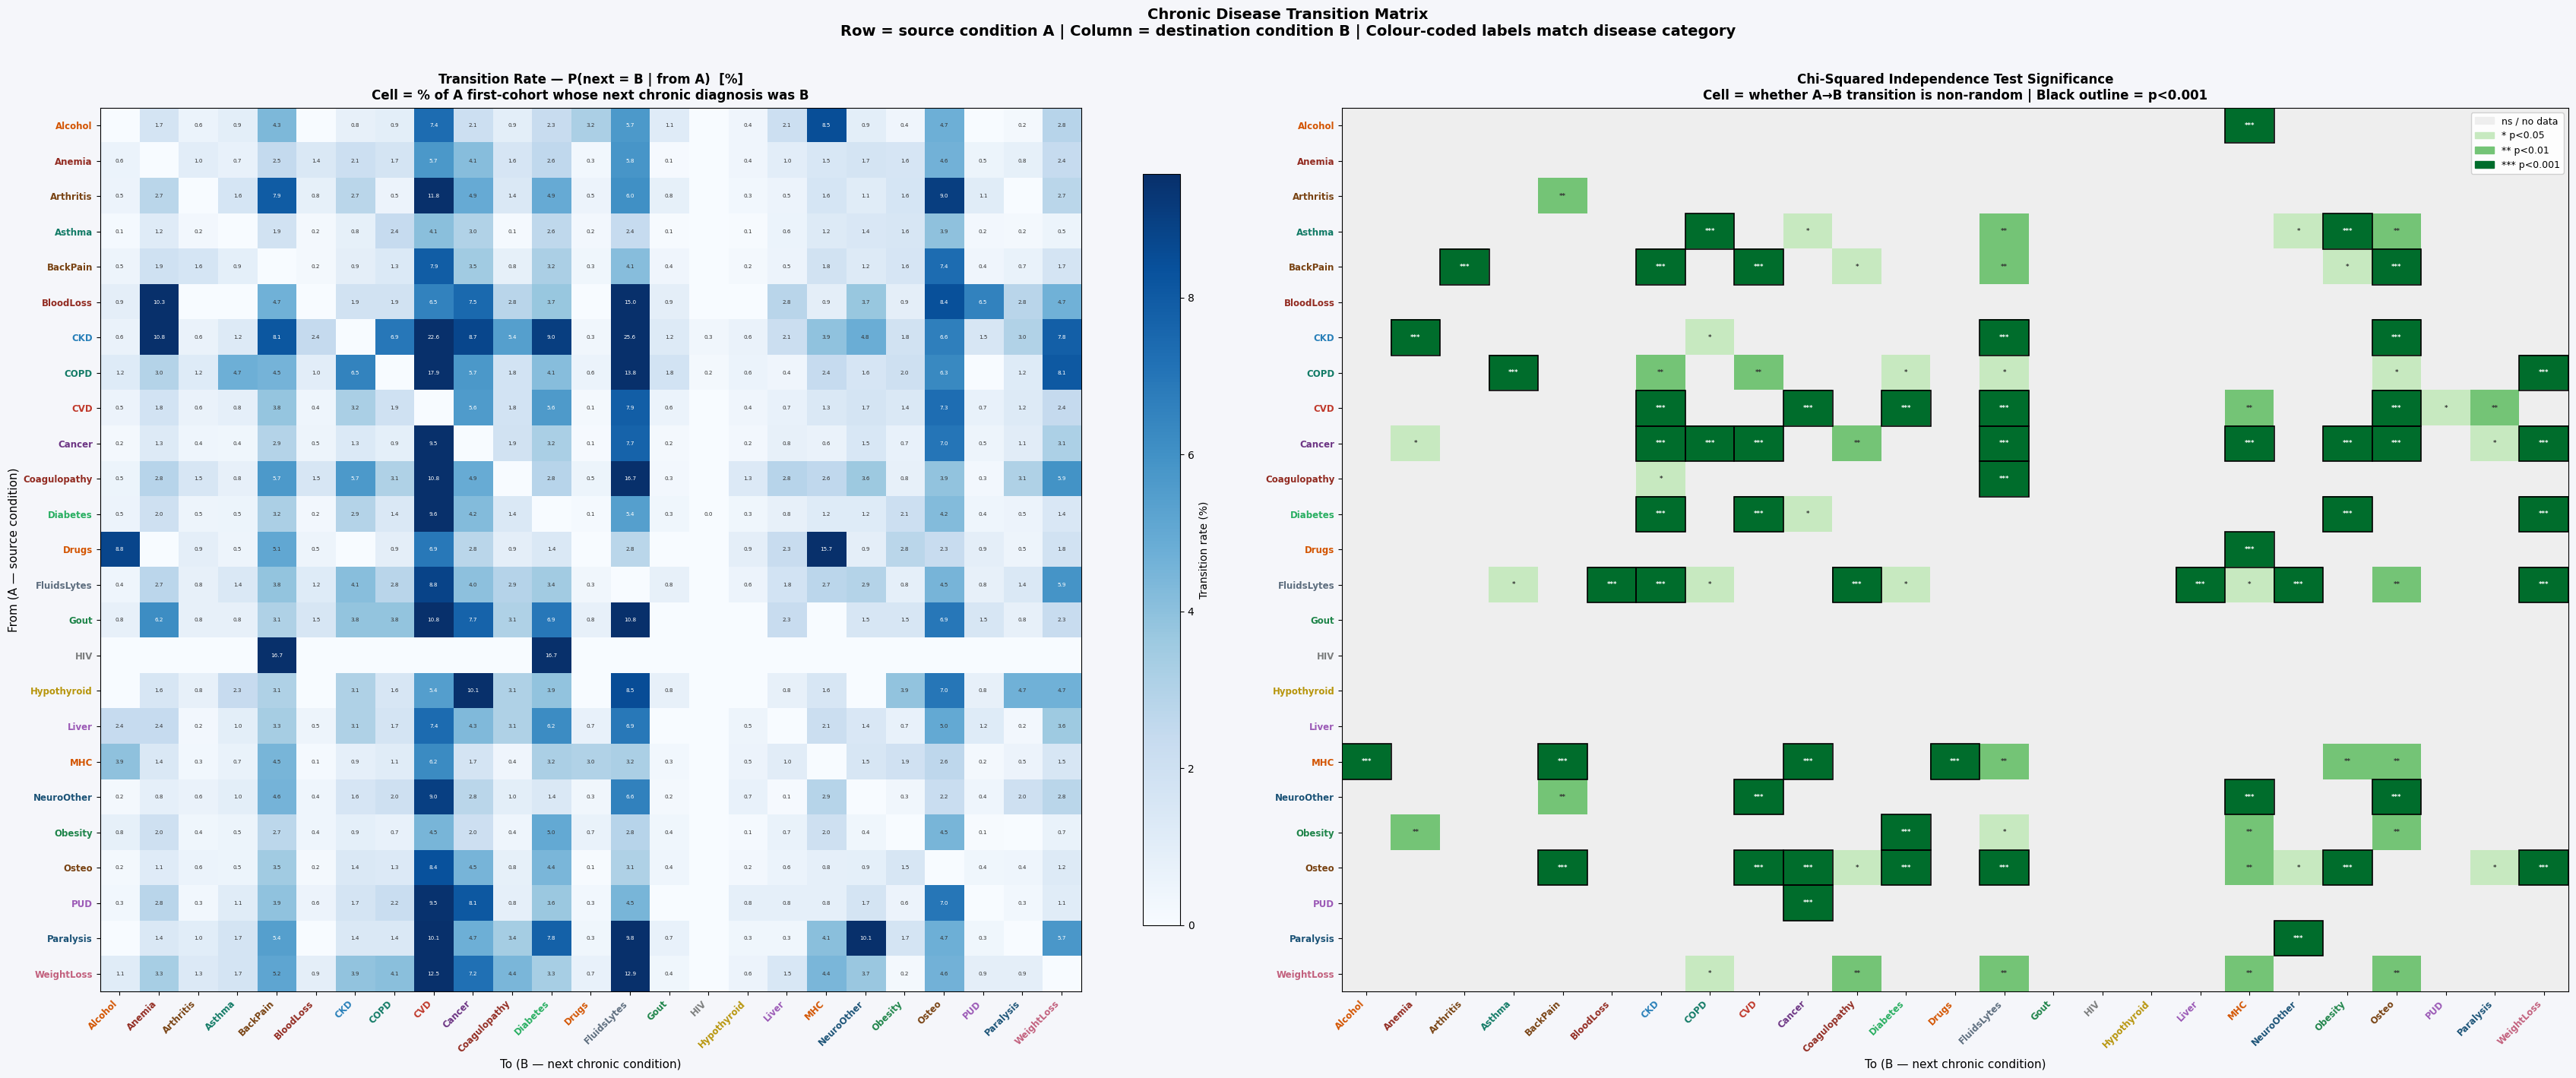

Heatmap saved → heatmap_rate_significance.png


In [11]:
# ── Transition heatmap (rate + significance) ──────────────────────────────────
conds_s = sorted(ALL_CONDS)
ci = {c: i for i, c in enumerate(conds_s)}
N_C = len(conds_s)

rate_mat = np.full((N_C, N_C), np.nan)
sig_mat  = np.full((N_C, N_C), np.nan)  # 0=ns, 1=*, 2=**, 3=***

for (a, b), cnt in direct_trans.items():
    if a not in ci or b not in ci: continue
    tf = first_cohort.get(a, 0)
    if tf > 0: rate_mat[ci[a]][ci[b]] = cnt / tf * 100
    s = CHI2.get((a, b), {}).get('sig', 'ns')
    sig_mat[ci[a]][ci[b]] = {'ns': 0, '*': 1, '**': 2, '***': 3}.get(s, 0)

fig, axes = plt.subplots(1, 2, figsize=(34, 14))
fig.patch.set_facecolor('#f5f6fa')

# ── Left: rate ─────────────────────────────────────────────────────────────────
ax = axes[0]; ax.set_facecolor('#f5f6fa')
vmax = float(np.nanpercentile(rate_mat[~np.isnan(rate_mat) & (rate_mat>0)], 96))
im = ax.imshow(np.nan_to_num(rate_mat, nan=0), cmap='Blues',
               aspect='auto', vmin=0, vmax=vmax)

thresh = vmax * 0.55
for i in range(N_C):
    for j in range(N_C):
        v = rate_mat[i][j]
        if np.isnan(v) or v < 0.01: continue
        fc = 'white' if v > thresh else '#333'
        ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=5.2, color=fc)

ax.set_xticks(range(N_C)); ax.set_yticks(range(N_C))
ax.set_xticklabels(conds_s, rotation=45, ha='right', fontsize=8.5)
ax.set_yticklabels(conds_s, fontsize=8.5)
for tick, cond in zip(ax.get_xticklabels(), conds_s):
    tick.set_color(COND_COL.get(cond,'#333')); tick.set_fontweight('bold')
for tick, cond in zip(ax.get_yticklabels(), conds_s):
    tick.set_color(COND_COL.get(cond,'#333')); tick.set_fontweight('bold')
ax.set_xlabel('To (B — next chronic condition)', fontsize=11)
ax.set_ylabel('From (A — source condition)', fontsize=11)
ax.set_title('Transition Rate — P(next = B | from A)  [%]\n'
             'Cell = % of A first-cohort whose next chronic diagnosis was B',
             fontsize=12, fontweight='bold', pad=8)
plt.colorbar(im, ax=ax, shrink=0.85, label='Transition rate (%)')

# ── Right: significance ────────────────────────────────────────────────────────
ax = axes[1]; ax.set_facecolor('#f5f6fa')
sig_colours = ['#eeeeee', '#c7e9c0', '#74c476', '#006d2c']
sig_labels  = ['ns / no data', '* p<0.05', '** p<0.01', '*** p<0.001']
cmap_sig = mcolors.ListedColormap(sig_colours)
im2 = ax.imshow(np.nan_to_num(sig_mat, nan=0), cmap=cmap_sig,
                aspect='auto', vmin=0, vmax=3)

for i in range(N_C):
    for j in range(N_C):
        v = sig_mat[i][j]
        r = rate_mat[i][j]
        if np.isnan(v) or np.isnan(r) or r < 0.01: continue
        lbl = ['','*','**','***'][int(v)]
        ax.text(j, i, lbl, ha='center', va='center', fontsize=6,
                color='white' if v==3 else '#333', fontweight='bold')
        if v == 3:
            ax.add_patch(plt.Rectangle((j-0.5, i-0.5), 1, 1,
                         fill=False, edgecolor='black', lw=1.2, zorder=3))

ax.set_xticks(range(N_C)); ax.set_yticks(range(N_C))
ax.set_xticklabels(conds_s, rotation=45, ha='right', fontsize=8.5)
ax.set_yticklabels(conds_s, fontsize=8.5)
for tick, cond in zip(ax.get_xticklabels(), conds_s):
    tick.set_color(COND_COL.get(cond,'#333')); tick.set_fontweight('bold')
for tick, cond in zip(ax.get_yticklabels(), conds_s):
    tick.set_color(COND_COL.get(cond,'#333')); tick.set_fontweight('bold')
ax.set_xlabel('To (B — next chronic condition)', fontsize=11)
ax.set_title('Chi-Squared Independence Test Significance\n'
             'Cell = whether A→B transition is non-random | Black outline = p<0.001',
             fontsize=12, fontweight='bold', pad=8)
leg_s = [mpatches.Patch(color=c, label=l) for c, l in zip(sig_colours, sig_labels)]
ax.legend(handles=leg_s, fontsize=9, loc='upper right', framealpha=0.9)

plt.suptitle('Chronic Disease Transition Matrix\n'
             'Row = source condition A | Column = destination condition B | '
             'Colour-coded labels match disease category',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(BASE / 'heatmap_rate_significance.png', dpi=150,
            bbox_inches='tight', facecolor='#f5f6fa')
plt.show()
print('Heatmap saved → heatmap_rate_significance.png')

In [12]:
# ── Edge betweenness + Diabetes→CVD complete profile ─────────────────────────
edge_df = pd.DataFrame([
    {'from': a, 'to': b,
     'n_transitions':    cnt,
     'rate_pct':         round(cnt/first_cohort.get(a,1)*100, 3),
     'RR_dir':           round(RR_DIR.get((a,b),{}).get('rr', float('nan')), 3),
     'RR_sig':           RR_DIR.get((a,b),{}).get('sig','—'),
     'chi2':             round(CHI2.get((a,b),{}).get('chi2', float('nan')), 2),
     'chi2_p':           round(CHI2.get((a,b),{}).get('p', float('nan')), 6),
     'chi2_sig':         CHI2.get((a,b),{}).get('sig','—'),
     't_stat':           round(TTEST.get((a,b),{}).get('t', float('nan')), 3),
     't_sig':            TTEST.get((a,b),{}).get('sig','—'),
     'edge_betweenness': round(edge_bet.get((a,b), 0), 6)}
    for (a,b), cnt in sorted(DIR_FILT.items(), key=lambda x: -edge_bet.get(x[0],0))
]).sort_values('edge_betweenness', ascending=False).reset_index(drop=True)

print('TOP 30 EDGES BY BETWEENNESS CENTRALITY')
print('=' * 105)
print(f'  {"Edge":<32}  {"n":>6}  {"rate%":>6}  {"RR_dir":>7}  {"RR_sig":>6}  '
      f'{"chi2":>8}  {"chi2_sig":>8}  {"edge_bet":>10}')
print('-' * 105)
for _, row in edge_df.head(30).iterrows():
    mark = '  ◄◄◄' if row['from']=='Diabetes' and row['to']=='CVD' else ''
    rr = f'{row.RR_dir:.2f}' if not pd.isna(row.RR_dir) else '  —'
    ch = f'{row.chi2:.1f}'   if not pd.isna(row.chi2)   else '  —'
    print(f'  {row["from"]:>14}→{row["to"]:<14}  {row.n_transitions:>6,}'
          f'  {row.rate_pct:>5.2f}%  {rr:>7}  {row.RR_sig:>6}'
          f'  {ch:>8}  {row.chi2_sig:>8}  {row.edge_betweenness:>10.6f}{mark}')

edge_df.to_csv(BASE / 'edge_metrics_complete.csv', index=False)
print('\nFull edge metrics saved → edge_metrics_complete.csv')

# ── Diabetes→CVD complete profile ─────────────────────────────────────────────
print()
print('═' * 60)
print('DIABETES → CVD COMPLETE NETWORK PROFILE')
print('═' * 60)
d_cvd = edge_df[(edge_df['from']=='Diabetes') & (edge_df['to']=='CVD')]
if not d_cvd.empty:
    r = d_cvd.iloc[0]
    rank_bet = int(edge_df.index[(edge_df['from']=='Diabetes')&(edge_df['to']=='CVD')][0])+1
    rank_rate = int((edge_df['rate_pct'] > r.rate_pct).sum()) + 1
    print(f'  n direct transitions       : {r.n_transitions:,}')
    print(f'  Transition rate            : {r.rate_pct:.2f}%  (rank {rank_rate}/{len(edge_df)} in full network)')
    print(f'  RR_dir                     : {r.RR_dir:.2f}  (sig: {r.RR_sig})')
    print(f'  Chi-squared statistic      : {r.chi2:.2f}  (p={r.chi2_p:.2e}, {r.chi2_sig})')
    print(f'  T-statistic                : {r.t_stat:.3f}  (sig: {r.t_sig})')
    print(f'  Edge betweenness           : {r.edge_betweenness:.6f}  (rank {rank_bet}/{len(edge_df)})')
    print(f'  Concurrent co-diagnoses    : {concurrent.get(frozenset(["Diabetes","CVD"]),0):,}')
    dm = metric_df[metric_df.condition=='Diabetes'].iloc[0]
    cm = metric_df[metric_df.condition=='CVD'].iloc[0]
    print()
    print('  DIABETES NODE METRICS:')
    print(f'    Betweenness: {dm.betweenness:.5f}  Closeness: {dm.closeness:.4f}  PageRank: {dm.pagerank:.5f}  In-deg: {dm.in_degree:.0f}  Out-deg: {dm.out_degree:.0f}')
    print('  CVD NODE METRICS:')
    print(f'    Betweenness: {cm.betweenness:.5f}  Closeness: {cm.closeness:.4f}  PageRank: {cm.pagerank:.5f}  In-deg: {cm.in_degree:.0f}  Out-deg: {cm.out_degree:.0f}')

TOP 30 EDGES BY BETWEENNESS CENTRALITY
  Edge                                   n   rate%   RR_dir  RR_sig      chi2  chi2_sig    edge_bet
---------------------------------------------------------------------------------------------------------
           Drugs→MHC                 34  15.67%     5.20     ***     215.3       ***    0.038333
           Osteo→Paralysis           23   0.43%     0.09     ***       4.5         *    0.038333
          Asthma→MHC                 21   1.22%     1.86      ns       1.3        ns    0.035833
             CVD→Hypothyroid         25   0.38%     0.07     ***       0.0        ns    0.035000
        Diabetes→Alcohol             22   0.55%     0.24     ***       0.2        ns    0.033333
             MHC→Drugs               46   3.01%     0.19     ***     353.6       ***    0.033333
          Cancer→PUD                 21   0.46%     0.06     ***       0.1        ns    0.033333
             MHC→Cancer              26   1.70%     2.69     ***      12.4  